# 장기 시계열 이상탐지 결과

한 Process가 며칠 동안 느려지거나, 시간당 실행 수가 여러 날 계속 바뀌는 현상을 **오프라인 배치**로 분석한다.

기존 IF·K-means·LOF와 분리한 실험이다. 실제 로그의 분포를 참고한 **직접 생성 반합성 데이터**이며, 실제 운영 장애에서 검증한 결과는 아니다. 이 노트북은 고정된 결과를 읽고 설명할 뿐 재학습·기준 조정을 하지 않는다.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'code' / 'long_term_anomaly').is_dir())
sys.path.insert(0, str(ROOT / 'code'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from long_term_anomaly import report
from long_term_anomaly.common import REPORT, DATA, read_json
results, package = report.context()
primary = results['primary']
def show(fig):
    display(fig)
    plt.close(fig)
display(Markdown(f"선정한 장기 모델: **{report.NAMES[primary]}**"))

선정한 장기 모델: **STL + PELT**

## 1. 지금 데이터로 어떤 모델을 선택할 수 있나?

기간의 길이와 연속 관측의 길이는 다르다. 아래 비중은 달력상 시간 중 로그가 한 건이라도 있는 시간의 비중이다. **빈 시간 전체를 입력 중단 장애로 해석하면 안 된다.** 수집 공백인지 실제 무실행인지 알 수 없기 때문이다.

,수집 폴더,첫 관측,마지막 관측,로그 있는 시간 수,달력상 시간 수,로그 있는 시간 비중,로그 있는 날짜 수,전체 로그 최장 연속 시간
0,25년12월24일-26년4월6일,2025-12-24 10:00:00,2026-04-06 08:00:00,396,2471,0.160259,60,119
1,26년8월15일-26년9월14일,2026-08-15 00:00:00,2026-09-14 14:00:00,258,735,0.351020,19,231
2,26년9월30일-26년10월2일,2026-09-30 09:00:00,2026-10-02 15:00:00,13,55,0.236364,3,4


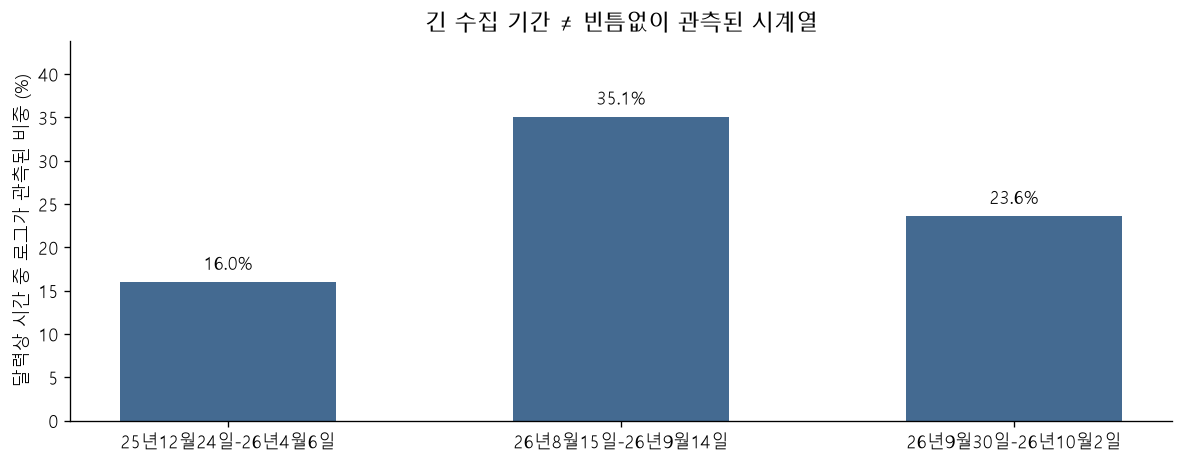

,확인한 항목,값
0,개별 Adapter+Process 최장 연속 관측,159시간
1,7일 연속 정상 후보 집단,0
2,28일 연속 정상 후보 집단,0


In [2]:
display(report.source_table())
show(report.source_plot())
support = pd.read_csv(REPORT / 'series_support.csv')
display(pd.DataFrame({
    '확인한 항목': ['개별 Adapter+Process 최장 연속 관측', '7일 연속 정상 후보 집단', '28일 연속 정상 후보 집단'],
    '값': [f"{support.longest_hour_run.max()}시간", int((support.longest_hour_run >= 168).sum()), int((support.longest_hour_run >= 672).sum())]
}))

### 선택 근거

- **STL:** 정상 참고 구간을 시간대 패턴·기준 수준으로 분리한다. 이후 관측값이 이 기준과 얼마나 다른지 계산한다.
- **PELT:** 분석 구간을 보며 평균이나 변동성이 바뀐 지점을 찾아 나눈다. ‘한 번 튐’과 ‘여러 날 지속된 변화’를 구별할 근거를 준다.
- **STL + 장기 시간창:** 변화점 없이 6·12·24시간 단위로 지속성을 보는 비교 모델이다.
- **시간대 단순 기준:** 장기 처리를 넣지 않은 단순 비교 기준이다. 이 모델까지 좋은 성능이 보장되지는 않는다.

주·월 단위 연속 이력이 충분하지 않아 DLinear·PatchTST 같은 신경망을 이번 실제 로그로 충분히 학습·검증했다고 주장하지 않는다. 주간 주기도 확인되지 않았으므로 기본 일주기 후보만 사용했다. 일주기가 모든 업무에서 입증되었다는 뜻도 아니다.

## 2. 평가셋은 어떻게 만들었나?

원본 초기 구간에서 S·정수/비음수 건수·오류 0 등 조건을 만족한 **정상 후보**의 시간당 집계로 중심·변동 폭·짧은 시간 간 상관을 추정했다. 이후 연속 6주와 장기 장애 구간을 직접 시뮬레이션했다.

**28일은 생성한 정상 참고 구간, 뒤 14일은 판정 대상**이다. 실제 원본에 6주 연속 기록이 있다는 뜻이 아니다. 정상에도 작은 추세 변화·일시적인 변동·짧은 급등을 포함했다. ADBench의 표 형식 행을 임의로 이어 붙인 시계열이 아니다.

injected,정상 사례,이상 주입 사례
split,,
train,64,0
calibration,48,0
development,144,144
test,288,288


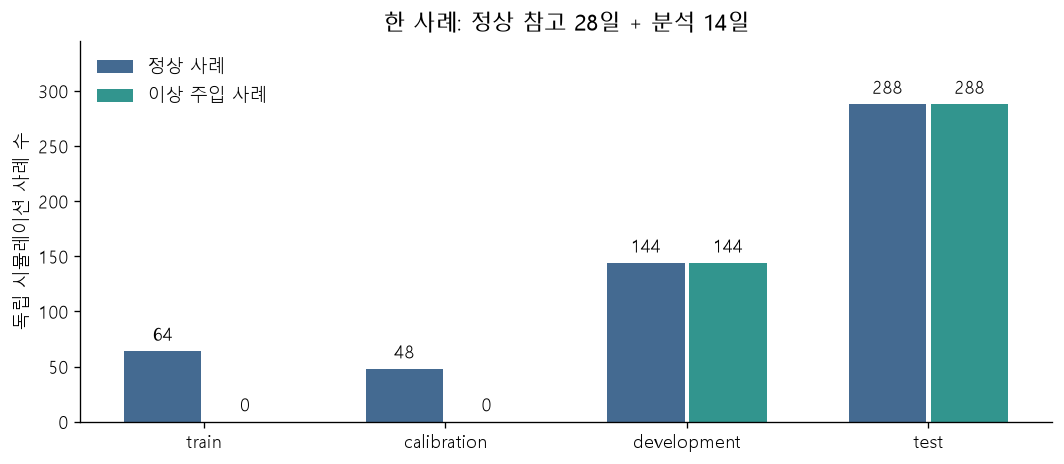

,분포 추정 집계 수,참고 집단 수,원본 분포 추정 종료 시각 (미포함),생성기
0,7894,82,2026-02-22 01:00:00,직접 작성 / 공식 ADBench 데이터 아님


In [3]:
display(report.composition())
show(report.composition_plot())
source = read_json(DATA / 'source_distribution.json')
display(pd.DataFrame([{
    '분포 추정 집계 수': source['fit_hourly_group_rows'],
    '참고 집단 수': source['reference_groups'],
    '원본 분포 추정 종료 시각 (미포함)': source['cutoff_exclusive'],
    '생성기': '직접 작성 / 공식 ADBench 데이터 아님'
}]))

학습·정상 보정에는 이상 주입 사례가 없다. 개발 데이터로 설정과 경보 기준을 고르고, 최종 평가에서는 고정된 기준만 적용했다. 정상/이상 짝은 같은 배경을 공유하되 **짝 전체가 한 파티션에만 속한다.** 생성 가정은 모든 파티션이 공유하므로, 이것만으로 다른 시스템의 실제 장애 성능이 입증되지는 않는다.

## 3. 입력과 파생 변수의 정확한 의미

이 모델의 입력은 원시 Process 한 행이 아니라 **같은 Adapter+Process의 시간당 집계**다. 아래의 ‘실행 수’는 Transaction/API 요청 수가 아니라 Process 행 수다.

| 입력 | 원본에서 얻는 값 | 역할 |
|---|---|---|
| `log_requests` | log(1 + 시간당 정상 후보 Process 행 수) | 장기 폭주·입력 감소 비교 |
| `log_duration_ms` | 시간당 각 행의 log(1 + endTime−startTime[ms]) 평균 | 소요시간 수준·변동성 비교 |
| `log_items_per_process` | 시간당 각 행의 log(1 + totalCount) 평균 | 처리 건수에 따른 소요시간 차이를 보정하는 조건 |
| `collection_observed` | 수집 여부가 알려진 시간인지 | 결측을 0건으로 오인하지 않기 |
| `latency_available` | 실행이 있어 소요시간을 알 수 있는지 | 무실행을 0ms로 오인하지 않기 |

`log_duration_ms`는 **소요시간 산술평균의 로그가 아니다.** 각 Process 시간에 로그를 취한 뒤 평균한 값이다. 처리 건수는 단독 이상 목표가 아니라 조건부 비교를 위한 값이다.

추가로 시간창 평균 편차, 시간창 변동 에너지, PELT 구간별 평균 편차·에너지를 만든다. ‘에너지’는 편차 제곱의 평균에 제곱근을 취한 값으로, 평균이 비슷해도 흔들림이 커졌는지 보기 위한 수치다.

In [4]:
record = package['models'][primary].record()
display(pd.DataFrame([record['setting']]))
display(pd.DataFrame({'점수 항목': record['feature_names'], '정상 참고 중앙값': record['normal_component_center'], '정상 P95−중앙값 (최소 폭 적용)': record['normal_component_spread']}))
print('에너지 항목 가중치:', record['energy_weight'])
print('고정된 실제 경보 기준:', round(record['threshold'], 6))

,method,context_hours,period,window,energy_window,penalty_factor,min_segment,jump,workload_conditioning
0,stl_pelt,672,24,12,24,2,12,3,True


,점수 항목,정상 참고 중앙값,정상 P95−중앙값 (최소 폭 적용)
0,local_level:requests,0.363657,0.647156
1,local_level:duration,0.435245,0.967758
2,local_level:items_per_process,0.315993,0.818707
3,local_energy:requests,1.017174,0.704267
4,local_energy:duration,1.055765,0.638333
5,local_energy:items_per_process,0.365760,1.303277
6,segment_level:requests,0.177332,0.246406
7,segment_level:duration,0.165395,0.528727
8,segment_level:items_per_process,0.267210,0.689375
9,segment_energy:requests,1.084388,0.303839


에너지 항목 가중치: 1.0
고정된 실제 경보 기준: 2.160511


## 4. 최종 성능 — 중앙값과 전체 지표는 다르다

Accuracy는 전체 판정의 정확도, Precision은 경보 중 실제 이상 비중, Recall은 실제 이상을 찾은 비중, F1은 Precision과 Recall의 조화 평균이다. **네 지표는 높을수록, 오탐률은 낮을수록 좋다.**

아래 네 지표는 여섯 시나리오의 지표를 계산한 뒤 얻은 중앙값이다. 오탐률은 정상 시간 중 잘못 경보한 비중이며, 전체 값과 시나리오별 최댓값을 따로 보인다. 그림에는 실제 측정값만 표시했다.

,모델,Accuracy,Precision,Recall,F1,전체 오탐률,시나리오 최대 오탐률
0,시간대 기준 · 단순 비교,81.07,31.58,8.70,13.25,4.10,4.33
1,STL + 장기 시간창,93.40,80.12,80.13,79.53,3.68,5.63
2,STL + PELT,94.33,80.49,85.57,82.81,3.85,4.79


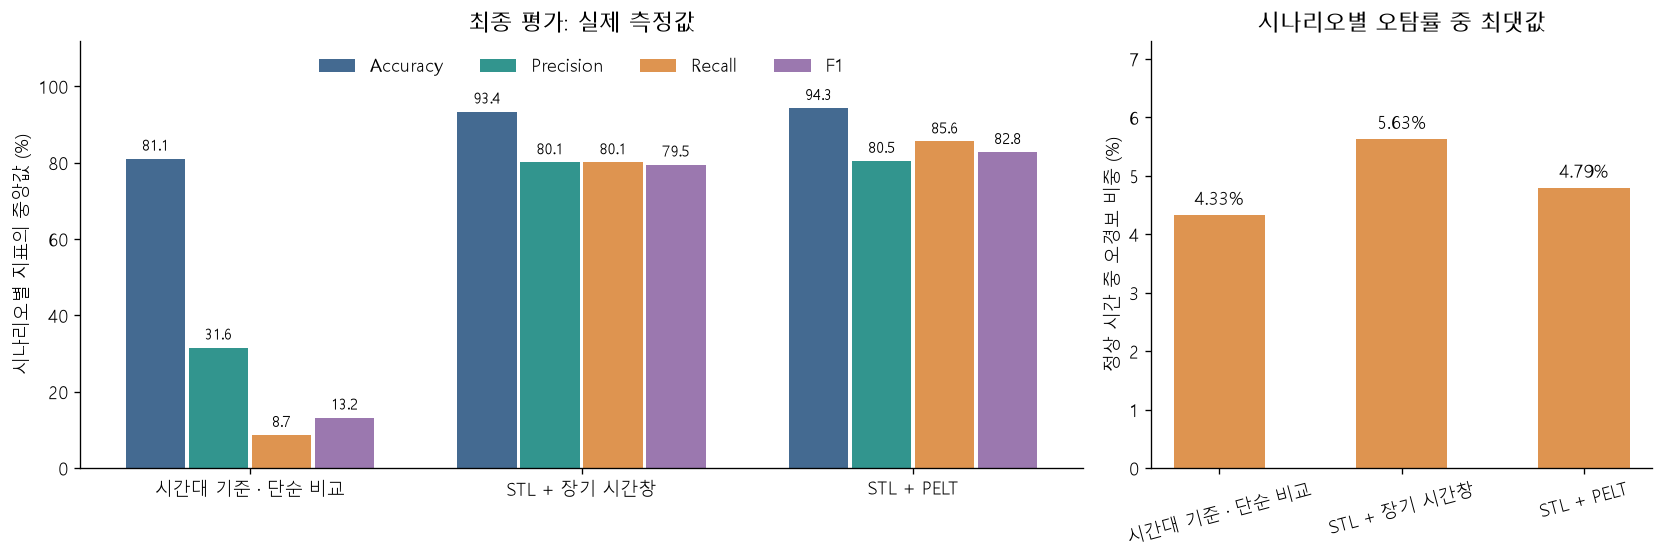

,accuracy,precision,recall,f1,false_positive_rate,tp,fp,tn,fn,assessed_hours,unassessable_hours
선정 모델 · 전체 시간 통합 지표,0.914626,0.797665,0.699108,0.745142,0.038538,23985,6084,151786,10323,192178,1358


In [5]:
display(report.model_table())
show(report.model_plot())
display(pd.DataFrame([results['results'][primary]['pooled']]).rename(index={0:'선정 모델 · 전체 시간 통합 지표'}))

## 5. 어떤 장기 현상을 잘 찾고, 무엇을 놓쳤나?

한 시간의 적중을 이상 기간 전체의 적중으로 늘리지 않았다. 각각의 원래 시간별 정답으로 계산했다. 짧은 수집 결측 시간과 앞선 28일 정상 참고 구간은 분모에서 제외했다. 정상 비중이 높으므로 Accuracy만 보고 판단하면 안 된다.

,시나리오,Accuracy,Precision,Recall,F1,오탐률,탐지 시간,놓친 시간,오경보 시간
0,일일 패턴 변화,77.80,64.45,24.78,35.79,4.55,1980,6011,1092
1,점진적 악화,89.38,77.15,63.01,69.37,4.40,3859,2265,1143
2,지속 지연,94.61,83.89,83.40,83.65,3.17,4417,879,848
3,지속 입력 감소,96.95,85.48,96.65,90.72,3.00,4788,166,813
4,지속 폭주,95.98,83.84,92.06,87.76,3.30,4617,398,890
5,변동성 증가,94.06,76.91,87.74,81.97,4.79,4324,604,1298


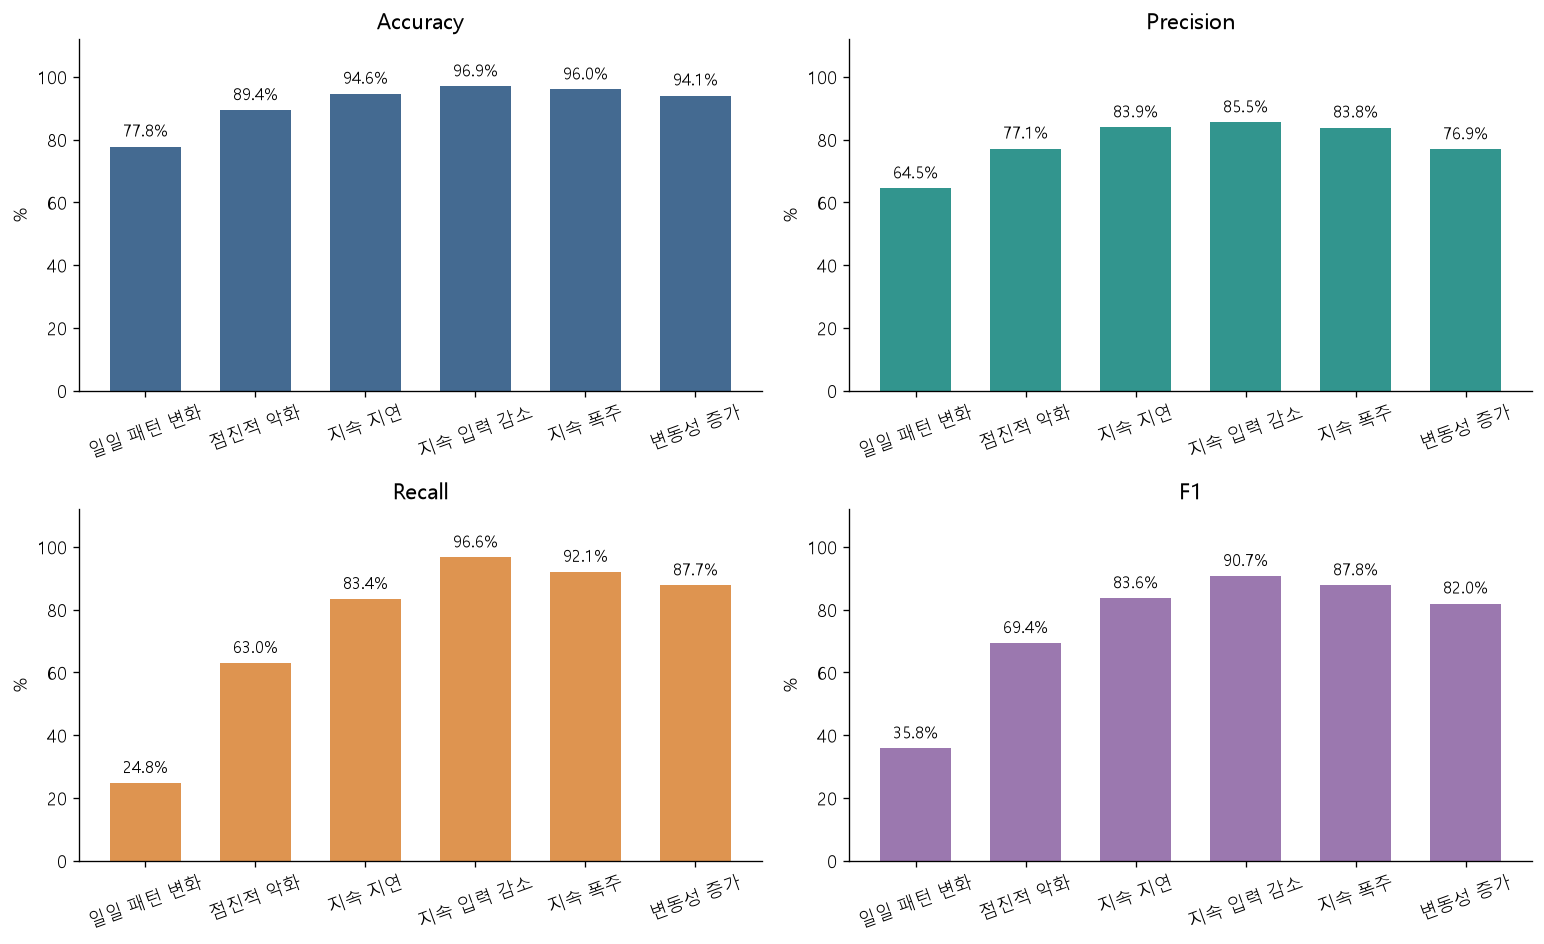

In [6]:
display(report.scenario_table())
show(report.scenario_plot())

## 6. 점수 분포와 경보 기준은 어떻게 읽나?

파랑은 정상 시간, 주황은 주입한 이상 시간이다. 각 막대의 높이는 각 집단 전체 중 해당 점수 구간의 비중이다. **점수가 실제 경보 기준보다 높으면 이상 경보**다. 두 분포가 겹치는 부분에서 오탐·미탐이 생긴다. 이상 점수는 장애 확률이 아니다.

표시 범위 밖 극단값도 평가에는 포함했다. 점선은 성능 목표가 아니라 실제로 적용한 경보 기준이다.

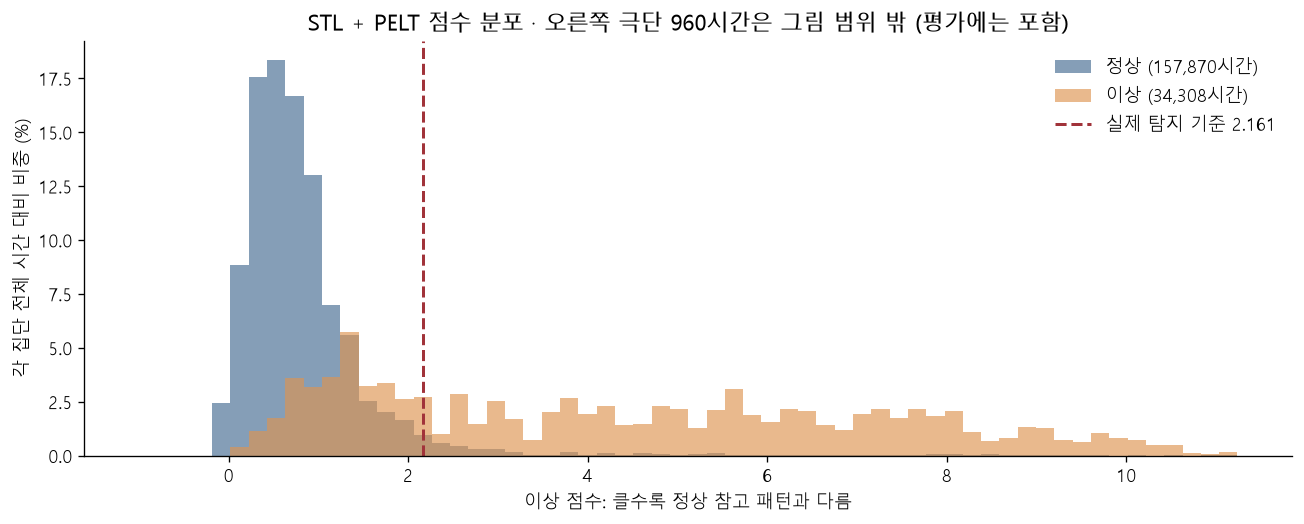

In [7]:
show(report.score_histogram())

## 7. 실제 시계열 사례

각 시나리오에서 파일 순서상 **첫 번째 이상 주입 사례**를 표시한다. 잘 탐지한 사례를 골라낸 것이 아니다. 주황 배경은 정답 구간, 회색은 수집 결측이다. 위는 관측값과 정상 기준, 아래는 이상 점수와 경보 기준이다.

PELT와 중심 시간창은 뒤쪽 시간도 함께 사용한다. 이 그래프는 14일 구간을 본 뒤 내리는 **사후 판정**이지, 당시 시점에 이미 경보했다고 주장하는 그래프가 아니다.

In [8]:
examples = report.timeline_examples()
plt.close('all')  # 아래에서 시나리오별로 한 번씩만 표시

### 지속 지연

소요시간이 여러 날 높은 수준에 머문다. 정상 기준과의 차이가 잠깐이 아니라 구간으로 유지되는지를 본다.

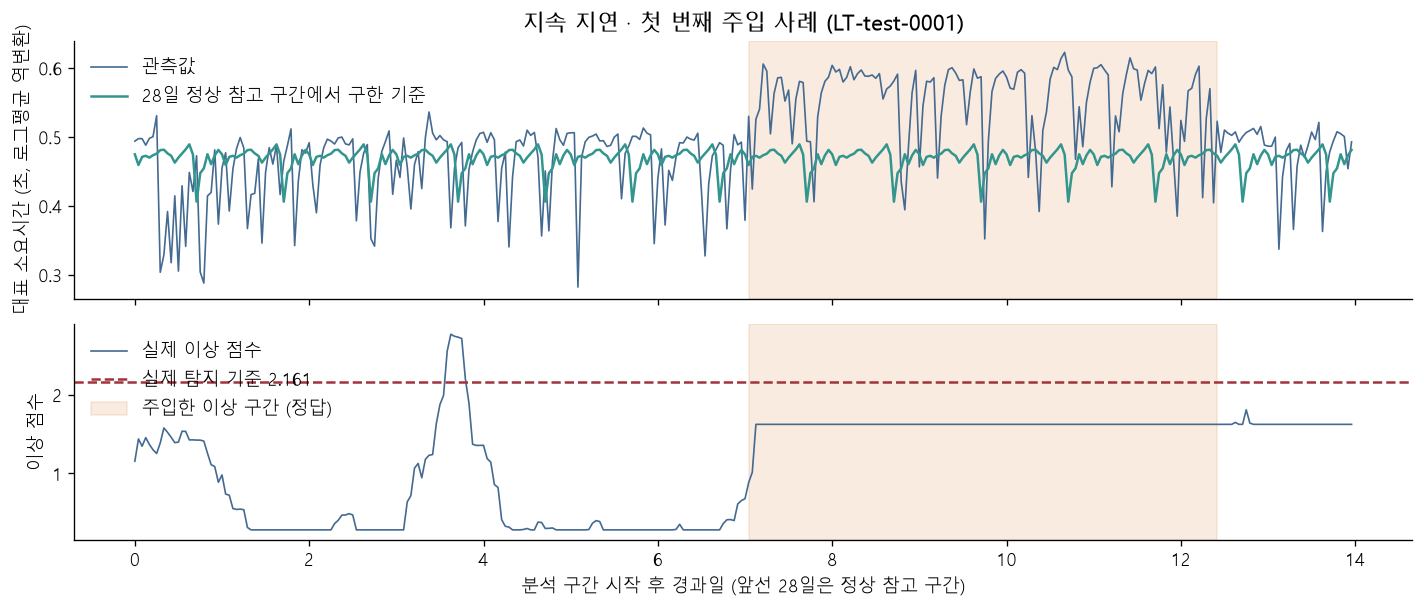

In [9]:
show(examples[0])

### 점진적 악화

며칠에 걸쳐 서서히 느려진다. 초반의 아주 약한 변화는 놓칠 수 있다. 초반도 정답 이상 구간에서 제외하지 않았다.

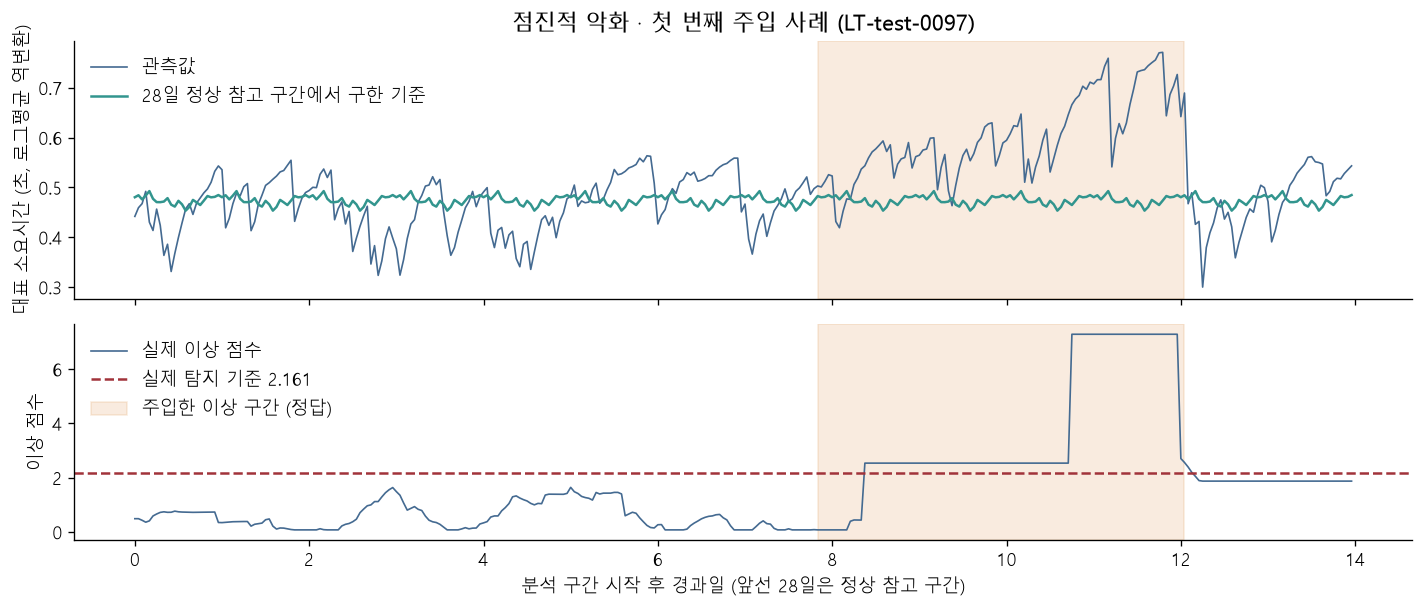

In [10]:
show(examples[1])

### 지속 폭주

시간당 Process 실행 수가 여러 날 높아진다. 단순히 실행 수가 많다는 이유가 아니라 이 실행 종류의 정상 기준과 비교한다.

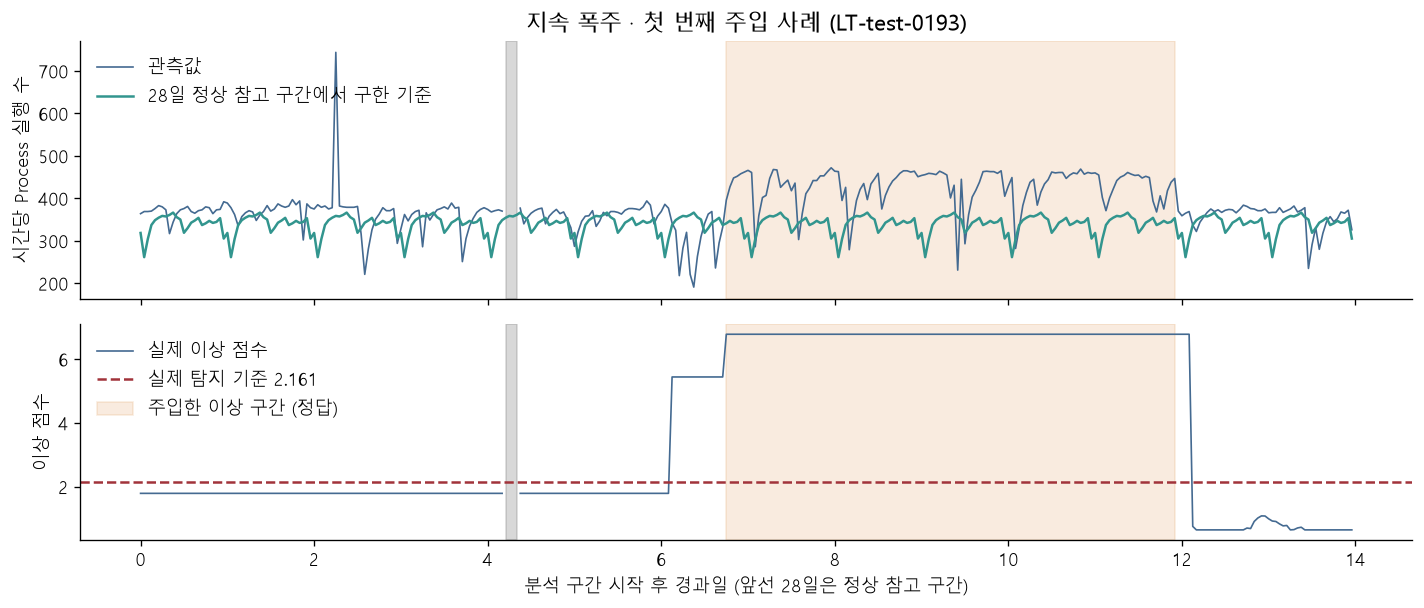

In [11]:
show(examples[2])

### 지속 입력 감소

수집은 정상으로 설정했는데 실행 수가 계속 줄어든다. 실제 운영에서 수집 상태를 모르면 입력 중단인지 수집 장애인지 확정할 수 없다.

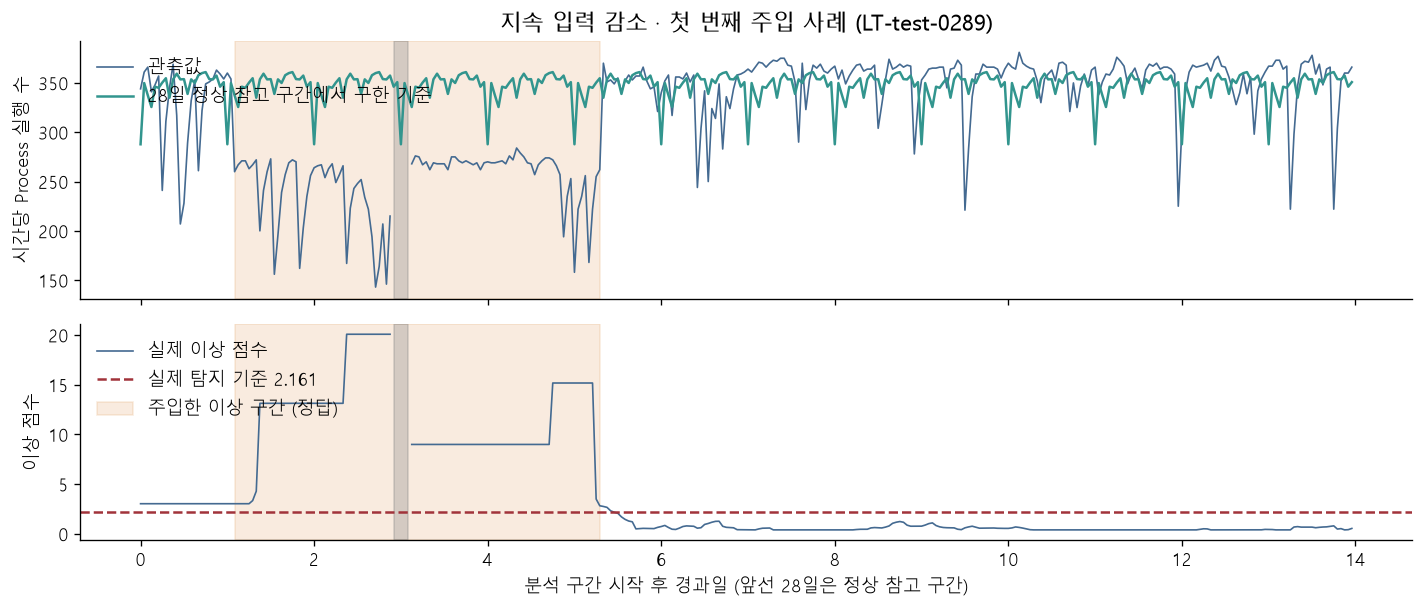

In [12]:
show(examples[3])

### 일일 패턴 변화

하루 안의 실행 패턴이 달라진 상태가 여러 날 반복된다. 증가와 감소가 상쇄되어 전체 평균만으로는 놓칠 수 있다.

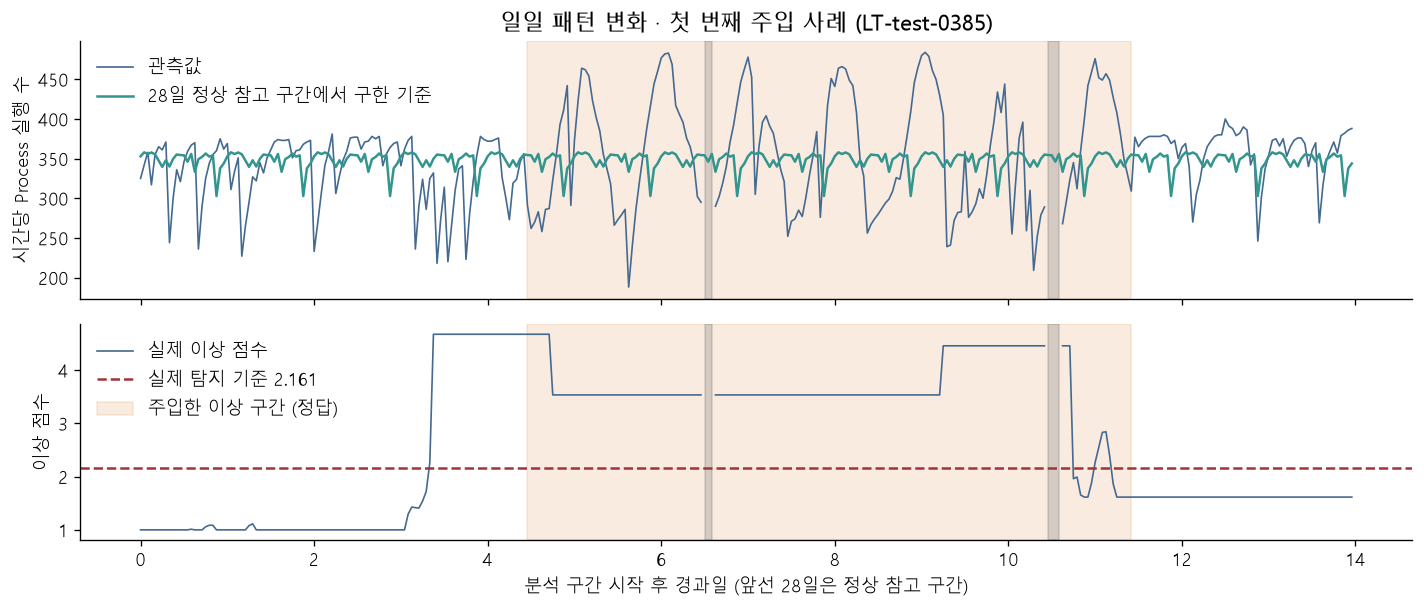

In [13]:
show(examples[4])

### 변동성 증가

평균 소요시간 변화보다 흔들림이 커진다. 편차 제곱을 사용하는 에너지 점수가 도움이 되는지 확인한다.

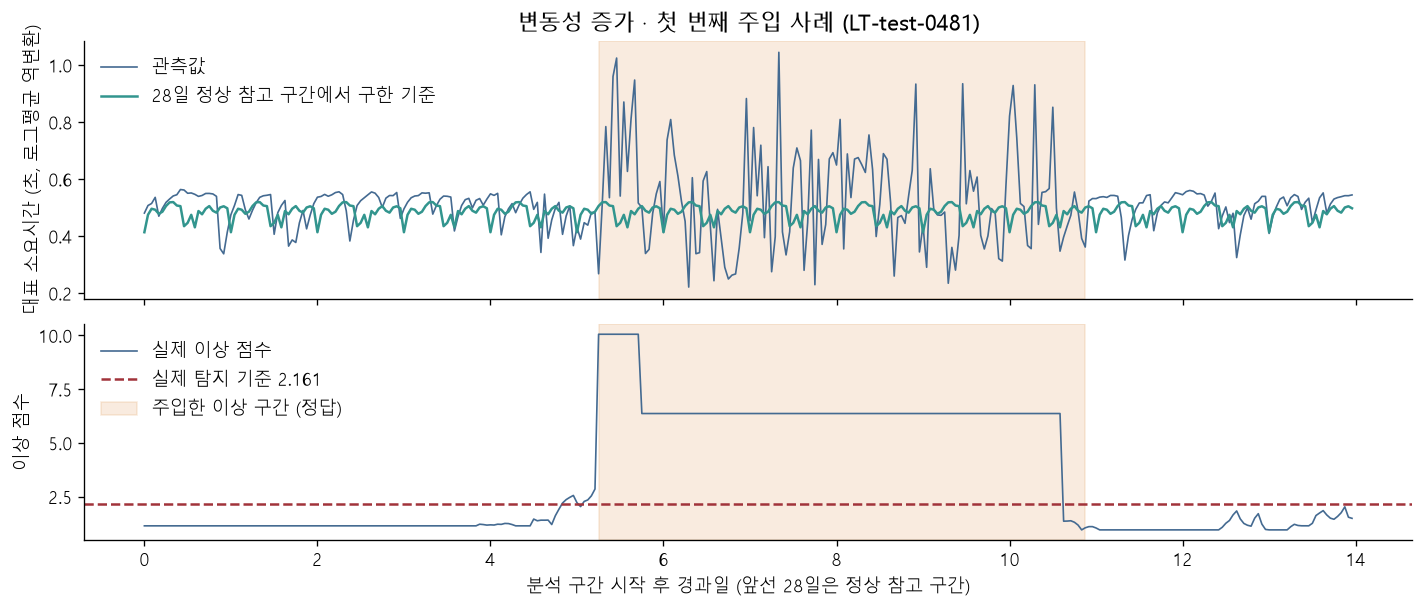

In [14]:
show(examples[5])

## 8. 경보를 낸 직접 근거

`local_level`은 시간창의 지속 편차, `local_energy`는 시간창의 큰 흔들림, `segment_level`·`segment_energy`는 PELT가 나눈 구간의 편차·흔들림이다. `requests`는 Process 실행 수, `duration`은 소요시간이다.

가장 크게 기여한 점수 항목을 집계했다. 이것은 **모델이 경보한 수치적 이유**이며, 장애 원인을 확정한 설명이나 시나리오 분류 정답은 아니다.

,판정,주요 점수 근거,시간 수
7,오탐 FP,segment_level:requests,2238
4,오탐 FP,segment_energy:duration,1920
6,오탐 FP,segment_level:duration,736
5,오탐 FP,segment_energy:requests,487
3,오탐 FP,local_level:requests,401
0,오탐 FP,local_energy:duration,234
1,오탐 FP,local_energy:requests,52
2,오탐 FP,local_level:duration,16
12,정탐 TP,segment_energy:duration,12001
15,정탐 TP,segment_level:requests,9604


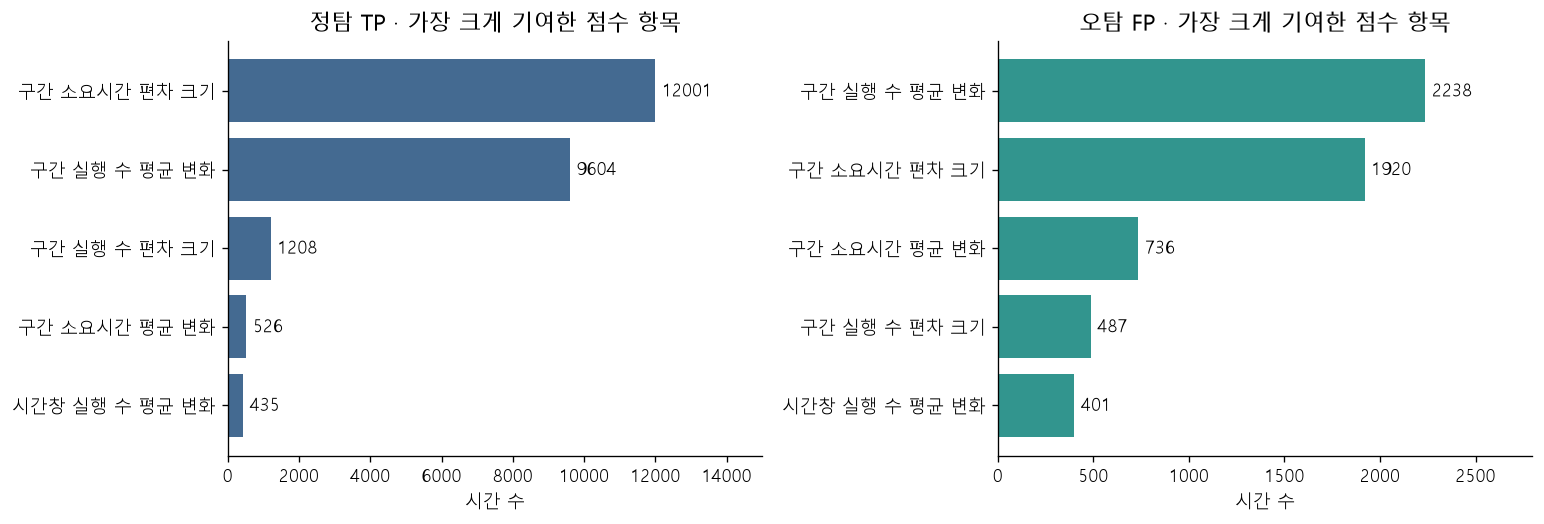

In [15]:
reasons = report.reasons_table()
display(reasons)
show(report.reason_plot(reasons))

## 9. 표본 불확실성과 한계

같은 시계열 안의 시간들은 서로 관련돼 있다. 시간을 독립 표본처럼 뽑지 않고 정상/이상 짝 단위 bootstrap으로 중앙값의 변동 범위를 보았다. 이 구간 역시 **같은 합성 생성 가정 안에서의 불확실성**일 뿐 실제 운영 성능의 신뢰구간이 아니다.

- S도 느림·잠재 장애를 포함할 수 있다. 정상 참고 구간은 별도 검토가 필요하다.
- 참고 분포는 DB.READER 40개·DB.WRITER 40개·FILE.READER/FILE.WRITER 각 1개 집단에서 얻었다. SERVICE 등 모든 Adapter의 성능을 검증한 것은 아니다.
- 중앙값 조건 충족은 모든 시나리오가 70% 이상이라는 뜻이 아니다. 전체 통합 지표와 시나리오별 지표도 함께 봐야 한다.
- 6주 연속 이력은 생성한 것이다. 실제 원본의 주간·월간 패턴을 검증한 결과가 아니다.
- 입력 중단과 수집 장애를 구별하려면 수집 건강 정보가 필요하다.
- 원본보다 연속성이 풍부한 합성 평가이므로 실제 로그에 대한 전이 성능은 별도 확인해야 한다.
- 오프라인 판정이므로 실시간 탐지 지연을 이 결과로 판단하면 안 된다.

In [16]:
display(report.uncertainty())
primary_result = results['results'][primary]
display(Markdown('요청한 수치 조건 충족: **' + ('예' if primary_result['target_met'] else '아니오') + '**'))

,지표,측정 중앙값 (%),쌍 단위 bootstrap 하한 (%),쌍 단위 bootstrap 상한 (%)
0,Accuracy,94.33,92.80,95.55
1,Precision,80.49,76.42,84.54
2,Recall,85.57,79.80,89.88
3,F1,82.81,78.13,86.46


요청한 수치 조건 충족: **예**

## 10. 저장 모델과 향후 배치 연결

`models.joblib`는 정상 점수 통계·경보 기준·선택한 설정을 저장한다. STL의 시간대 패턴은 입력으로 받은 정상 참고 구간에 다시 적합한다. 고정된 대형 신경망 가중치 파일과는 다른 구조다.

`long_term_anomaly.inference.score_frame(model, hourly_dataframe)`가 검증된 진입점이다. 시간 순서·1시간 간격·결측 마스크·수치 적합성을 확인한다. Adapter+Process별 배치는 서로 섞지 않는다. 입력에는 정답·시나리오·주입 크기가 필요 없다.

```powershell
$env:PYTHONPATH='code'
./.analysis-venv/Scripts/python.exe -m long_term_anomaly.inference --model reports/long_term_anomaly/models.joblib --input data/evaluation_long_term/test_hourly.csv.gz --output reports/long_term_anomaly/batch_predictions.csv
```

최소 정상 참고 28일이 필요하다. 실제 원본이 현재 이 조건을 충족한다고 주장하지 않는다. 충분히 수집된 새 연속 구간과 검토된 정상 기준을 확보한 뒤 운영 검증을 진행해야 한다. 신뢰된 로컬 joblib 파일만 로드해야 한다.

## 근거 자료와 이번 적용 범위

- [Cleveland et al. (1990), STL: A Seasonal-Trend Decomposition Procedure Based on Loess — 공식 구현/참고문헌](https://www.statsmodels.org/stable/generated/statsmodels.tsa.seasonal.STL.html): 정상 시간대 패턴 분리에 적용.
- [Killick, Fearnhead & Eckley (2012), Optimal detection of changepoints with a linear computational cost](https://arxiv.org/abs/1101.1438): PELT 구간 분할에 적용. 정상/이상 경보 기준은 별도 보정한 것이며 원 논문이 정답을 제공하는 것은 아님.
- [ADBench (NeurIPS 2022) 공식 저장소](https://github.com/Minqi824/ADBench): 표 형식 벤치마크이므로 이번 장기 데이터 생성에는 직접 사용하지 않음. 이 데이터는 공식 ADBench 장기 데이터가 아님.
- [Kim et al. (AAAI 2022), Towards a Rigorous Evaluation of Time-series Anomaly Detection](https://arxiv.org/abs/2109.05257): point adjustment 없이 시간별 평가 적용.
- [DLinear 공식 구현](https://github.com/cure-lab/LTSF-Linear), [PatchTST 논문](https://arxiv.org/abs/2211.14730): 향후 연속 데이터가 충분해지면 비교할 후보. 이번 구현/성능 결과로 포함하지 않음.